# ЛАБОРАТОРНА РОБОТА № 4

## Візуальний аналіз даних та часові ряди — аналіз у двох середовищах

**Курс:** СК26 «Інтелектуальний аналіз та візуалізація даних»
**Кафедра систем штучного інтелекту, Національний університет «Львівська політехніка»**
**Оцінювання:** 4 бали

---

## Визначення варіанта

Заповніть три поля в клітинці нижче й виконайте обидві службові клітинки —
номер варіанта, ринок і товар визначаться автоматично.

In [279]:
# ── Заповніть три поля ──────────────────────────────────────────
SURNAME_NAME = 'Паничевська Ярина Ернестівна'      # прізвище та ім'я
GROUP        = 'ШІ-32'      # шифр групи, наприклад СШІ-31
NUMBER       = 15       # ваш номер за списком групи (1–30)

assert SURNAME_NAME.strip(), 'Впишіть прізвище та ім\'я'
assert GROUP.strip(),        'Впишіть групу'
assert isinstance(NUMBER, int) and 1 <= NUMBER <= 30, 'Номер має бути цілим від 1 до 30'
print('Дані прийнято:', SURNAME_NAME, '|', GROUP, '| номер', NUMBER)

Дані прийнято: Паничевська Ярина Ернестівна | ШІ-32 | номер 15


In [280]:
# ── Службова клітинка: визначення варіанта. Змінювати не потрібно ──
import json

VARIANTS = json.load(open('lr4_variants_student.json', encoding='utf-8'))
V = VARIANTS[NUMBER - 1]

MARKET, GOOD, GOOD_UA = V['ринок'], V['товар'], V['товар_укр']

print('=' * 72)
print(f'ВАРІАНТ {V["варіант"]}   ·   {SURNAME_NAME}   ·   {GROUP}')
print('=' * 72)
print()
print(f'   Ринок:  {MARKET}')
print(f'   Товар:  {GOOD_UA}   (у наборі даних: {GOOD})')
print()
print('Далі в роботі користуйтеся змінними MARKET і GOOD —')
print('тоді весь код автоматично працюватиме саме з вашим рядом.')
print()
print('Період: 03.2014 – 12.2017 · очікувана довжина ряду: 46 місяців')
print('Фолдів ретроспективної перевірки: 7 · горизонт: 3 місяці · ARIMA(1, 1, 1)')

ВАРІАНТ 15   ·   Паничевська Ярина Ернестівна   ·   ШІ-32

   Ринок:  Lviv
   Товар:  олія   (у наборі даних: Oil (sunflower) - Retail)

Далі в роботі користуйтеся змінними MARKET і GOOD —
тоді весь код автоматично працюватиме саме з вашим рядом.

Період: 03.2014 – 12.2017 · очікувана довжина ряду: 46 місяців
Фолдів ретроспективної перевірки: 7 · горизонт: 3 місяці · ARIMA(1, 1, 1)


> ⚠️ Якщо ці дві клітинки не виконано, усі подальші завдання не мають сенсу:
> перевіряти роботу будуть **за вашим варіантом**, а не за тим рядом, який ви оберете самі.

| | |
|---|---|
| **Дата здачі** | 10/28/2026 |
| **Підпис** | Паничевська Я.Е. |

---
## Мета роботи

Виконати повний цикл аналізу одного часового ряду **у двох середовищах** — у Python та в Orange —
і пояснити, чому однаково названі метрики в них дають різні числа.

## Вихідні дані

| Файл | Зміст |
|---|---|
| `ціни_україна_2014_2017.csv` | Роздрібні ціни на 25 товарів по 28 ринках України, щомісяця, 03.2014 – 12.2017 |
| `lr4_variants_student.json` | Розподіл варіантів (зчитується автоматично) |
| `ЛР4_помилковий_аналіз.ipynb` | Звіт колеги, який треба відрецензувати (завдання 8) |

Це той самий набір, з яким ми працювали на лекції 4. **Національне середнє в завданнях не використовується** —
ваш ряд це конкретний обласний ринок.

## Що здавати

1. **`ЛР4_Прізвище_Варіант.ipynb`** — цей зошит із вашим кодом, графіками та письмовими висновками.
2. **`ряд_для_orange.csv`** — експортований ряд (завдання 9).
3. **`потік_orange.ows`** — збережений потік Orange.
4. **Знімки екрана** з Orange для завдань 10–13 — вставте їх у зошит або додайте окремими файлами.

## Правила

* **Код пишете самостійно** — у цьому зошиті навмисно немає заготовок.
* **Користуватися штучним інтелектом дозволено**, але ви зобов'язані заповнити декларацію в кінці зошита.
* **Кожне число має супроводжуватися висновком словами.** Робота, у якій є графіки й таблиці,
  але немає письмових відповідей на поставлені питання, оцінюється як невиконана.
* Усі обчислення мають бути **відтворюваними**: зошит має виконуватися від початку до кінця
  командою *Restart & Run All* без помилок.

---
# ЧАСТИНА 1. Аналіз засобами Python

*Виконується аудиторно.*

## Завдання 1. Підготовка ряду

Витягніть із набору ряд свого варіанта — скористайтеся змінними `MARKET` і `GOOD`,
які визначилися у службовій клітинці, — і приведіть його до **повної місячної сітки**
з березня 2014 по грудень 2017.

**У звіті наведіть:**
1. скільки місяців у сітці та скільки з них мають вимір;
2. у якому саме місяці пропуск;
3. **чому** цей пропуск виник — і чи він у вашому ряді один.

> 💡 **Підказка.** Пропуск є в усіх без винятку рядах набору. Якщо ви знайшли більше одного — перевірте, чи правильно побудована сітка.

In [281]:
import pandas as pd

df = pd.read_csv('ціни_україна_2014_2017.csv')
df['date'] = pd.to_datetime(dict(year=df['рік'], month=df['місяць'], day=1))

raw = (df[(df['ринок'] == MARKET) & (df['товар'] == GOOD)]
       .set_index('date')['ціна'].sort_index())

grid = pd.date_range('2014-03-01', '2017-12-01', freq='MS')
y_raw = raw.reindex(grid)

print('Місяців у сітці:', len(grid), '| з виміром:', y_raw.notna().sum())
missing = y_raw[y_raw.isna()].index
print('Пропущені місяці в нашому ринку:', [d.strftime('%Y-%m') for d in missing])


rows_per_month = df.groupby('date').size().reindex(grid)
print('Місяці, яких немає в УСЬОМУ наборі:',
      [d.strftime('%Y-%m') for d in rows_per_month[rows_per_month.isna()].index])

Місяців у сітці: 46 | з виміром: 45
Пропущені місяці в нашому ринку: ['2017-08']
Місяці, яких немає в УСЬОМУ наборі: ['2017-08']


**Висновок до завдання 1:**
за серпень 2017 в усьому наборі немає жодного рядка даних. Виходить, що це системний пропуск.

## Завдання 2. Заповнення пропуску

Заповніть пропуск. Порівняйте **щонайменше три** способи: перенесення останнього значення,
лінійну інтерполяцію та ще один на ваш вибір.

**У звіті наведіть:**
1. значення, яке дає кожен спосіб;
2. який спосіб ви обрали і **чому саме його**;
3. за якої умови заповнювати пропуск було б **неприпустимо** — наведіть приклад із цього ж набору даних.

> 💡 **Підказка.** Третій пункт стосується не вашого ряду, а принципу. Згадайте, які області зникають із набору у 2014 році.

In [282]:
gap = missing[0]

ffill  = y_raw.ffill()[gap]
linear = y_raw.interpolate('linear')[gap]
aug_mean = y_raw[y_raw.index.month == gap.month].drop(gap).mean()

print(pd.Series({'перенесення': ffill, 'лінійна': linear, 'середнє інших серпнів': aug_mean}).round(3))

y = y_raw.interpolate('linear')    
y.index.freq = 'MS'
print('\nПропусків після заповнення:', y.isna().sum())

перенесення              31.413
лінійна                  31.515
середнє інших серпнів    27.229
dtype: float64

Пропусків після заповнення: 0


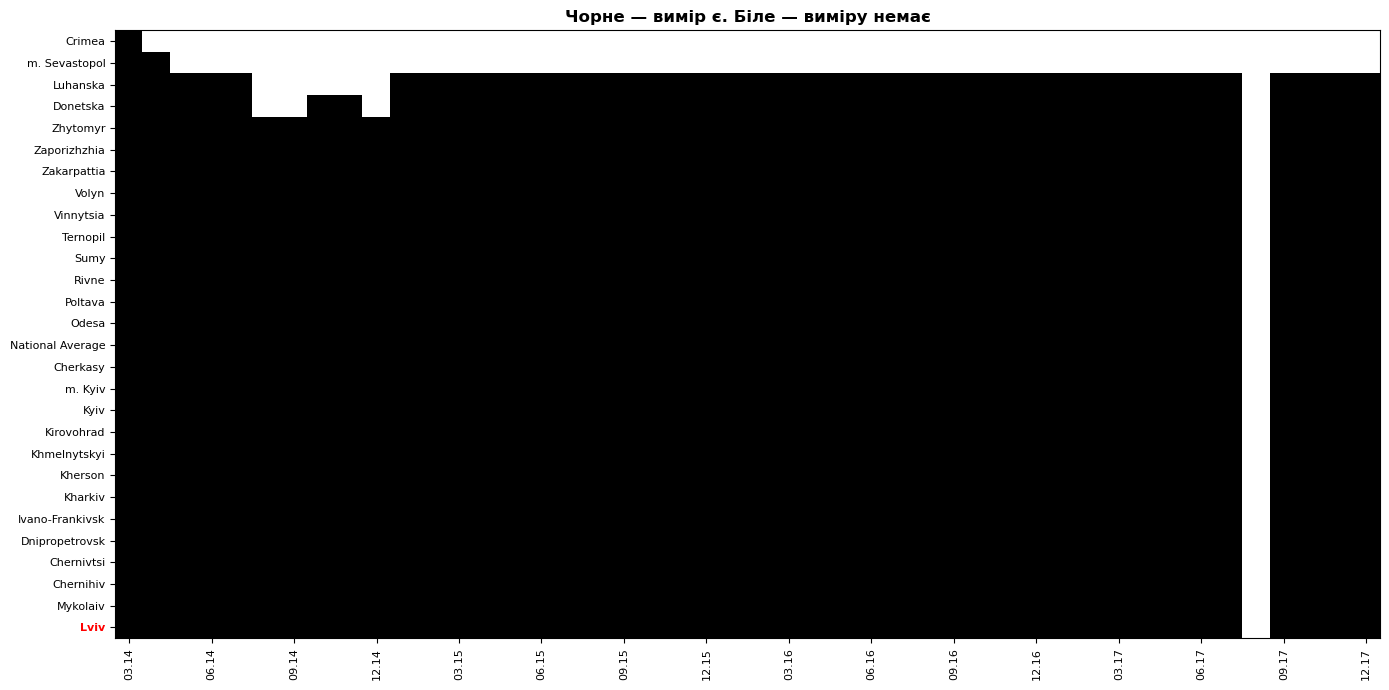

In [283]:
import matplotlib.pyplot as plt

presence = (df.groupby(['ринок', 'date']).size().unstack()
              .reindex(columns=grid)
              .notna().astype(int))
presence = presence.loc[presence.sum(axis=1).sort_values().index]

fig, ax = plt.subplots(figsize=(14, 7))
ax.imshow(presence.values, cmap='Greys', aspect='auto', interpolation='nearest', vmin=0, vmax=1)

ax.set_yticks(range(len(presence)))
ax.set_yticklabels(presence.index, fontsize=8)
for lbl in ax.get_yticklabels():
    if lbl.get_text() == MARKET:
        lbl.set_color('red'); lbl.set_fontweight('bold')

ticks = range(0, len(grid), 3)  
ax.set_xticks(ticks)
ax.set_xticklabels([grid[i].strftime('%m.%y') for i in ticks], rotation=90, fontsize=8)
ax.set_title('Чорне — вимір є. Біле — виміру немає', fontweight='bold')
plt.tight_layout()
plt.show()

**Висновок до завдання 2:** Для нашого пропуску (серпень 2017) було протестовано три способи заповнення:

| Спосіб | Значення, грн |
|---|---|
| перенесення останнього значення | 31.413 |
| лінійна інтерполяція | 31.515 |
| середнє інших серпнів | 27.229 |

Найкращою виявилася лінійна інтерполяція, тому що:
- по-перше, на відміну від перенесення, вона враховує не лише попередній місяць (липень), а й наступний (вересень), і ставить значення посередині між ними;
- по-друге, середнє інших серпнів дало 27.23 грн, що явно не відповідає рівню цін навколо пропуску (≈31.5 грн): воно включає серпень 2014 року, коли олія коштувала приблизно вдвічі дешевше.

Стосовно того коли неприпустимо заповнювати пропуски - коли спостереження припинилось через зовнішню причину, а не через збій запису. Я проглянула які ринки мали брак записів (менше ніж 45 місяців).
Таких ринків виявилось 4. На прикладі Криму та Севастополя у нас обриваються записи після 2014, бо після окупації ціни там більше не збирались. Якби ми ці пропуски заповнили якимось чином, ми б ставили вигадані ціни і проводити аналіз на таких даних не є хорошою ідеєю.

Стосовно Луганської та Донецької області, у нас є трохи більше записів, які тривають аж до 2017 року, проте з пропусками. Так само заповнювати не можна: відсутність виміру там означає, що ринку у звичному вигляді не було через бойові дії. Заповнивши ці місяці, ми вигадали б ціни, яких не існувало, і замаскували б подію, яка мала значний вплив на ціну (дефіцит, хаос).

У нас зовсім інша ситуація, ми побачили, що всюди відсутній серпень 2017, отже, можемо стверджувати це збоєм і заповнити.

## Завдання 3. Візуальна розвідка

Побудуйте **не менше трьох** графіків свого ряду, які відповідають на різні питання.

**У звіті наведіть:**
1. для кожного графіка — яке питання він ставить і **чому обрано саме таку геометрію та шкалу**;
2. одну знахідку, якої ви не очікували до побудови графіків.

> 💡 **Підказка.** Графік без пояснення вибору форми не зараховується. Нагадування з лекції: геометрія — це твердження про дані.

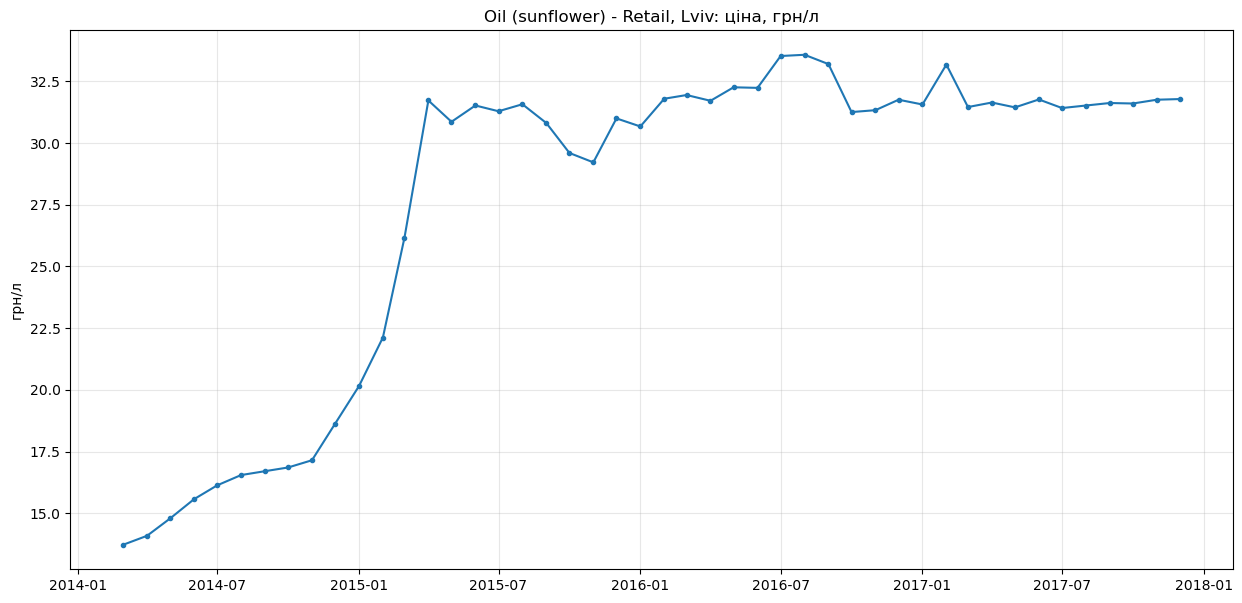

In [284]:
fig, ax = plt.subplots(figsize=(15, 7))
ax.plot(y.index, y.values, marker='o', ms=3)
ax.set_title(f'{GOOD}, {MARKET}: ціна, грн/л')
ax.set_ylabel('грн/л'); ax.grid(alpha=.3)
plt.show()

**Пояснення** 
Перший графік - зміна ціни за весь часовий проміжок. Обрано такий формат, оскільки час іде неперервно, тому точки з'єднано лінією: так видно, як ціна переходить з одного місяця в інший.
Шкала звичайна, у гривнях, бо нас цікавить саме ціна, яку бачить покупець. 

Питання, на яке відповідає графік: `як змінювався рівень ціни з 2014 по 2017 рік?`

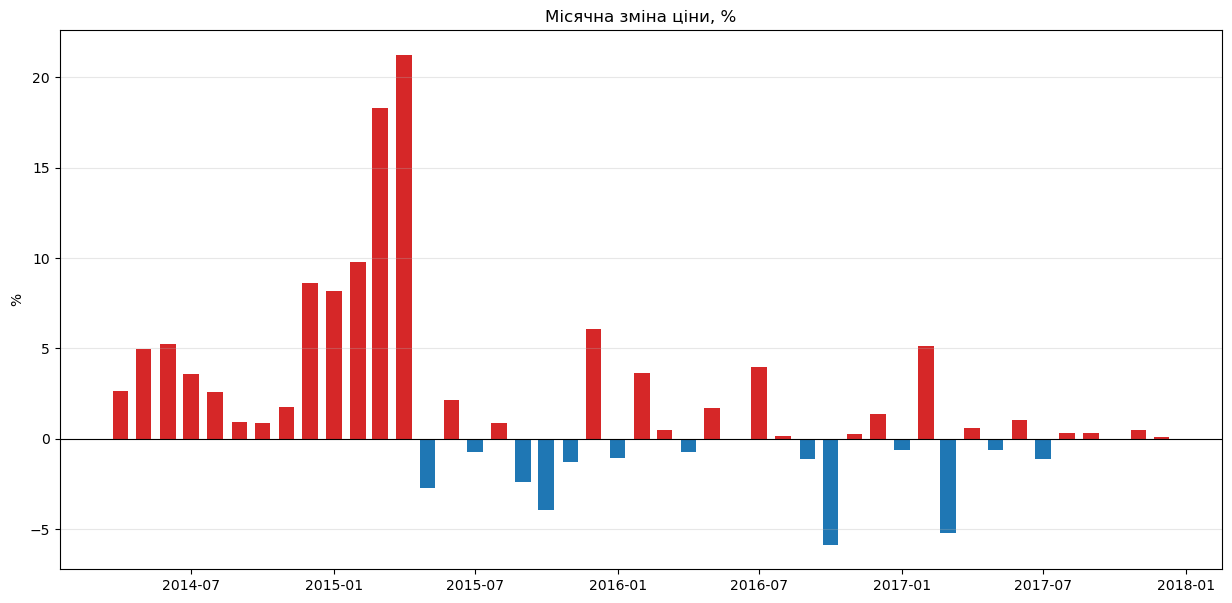

In [285]:
import numpy as np

pct = y.pct_change() * 100
fig, ax = plt.subplots(figsize=(15, 7))
ax.bar(pct.index, pct.values, width=20, color=np.where(pct > 0, 'tab:red', 'tab:blue'))
ax.axhline(0, color='k', lw=.8); ax.set_title('Місячна зміна ціни, %'); ax.set_ylabel('%')
ax.grid(alpha=.3, axis='y')
plt.show()

**Пояснення** 
Другий графік - місячна зміна ціни у відсотках. Обрано стовпці, бо кожна зміна — це окрема подія конкретного місяця, а не плавний процес. Відсотки замість гривень потрібні, щоб зміни 2014 року і 2017 року можна було порівняти між собою. 
Колір показує напрямок: червоний -> ціна зросла, синій -> впала.

Питання, на яке відповідає графік: `коли були різкі стрибки ціни?`

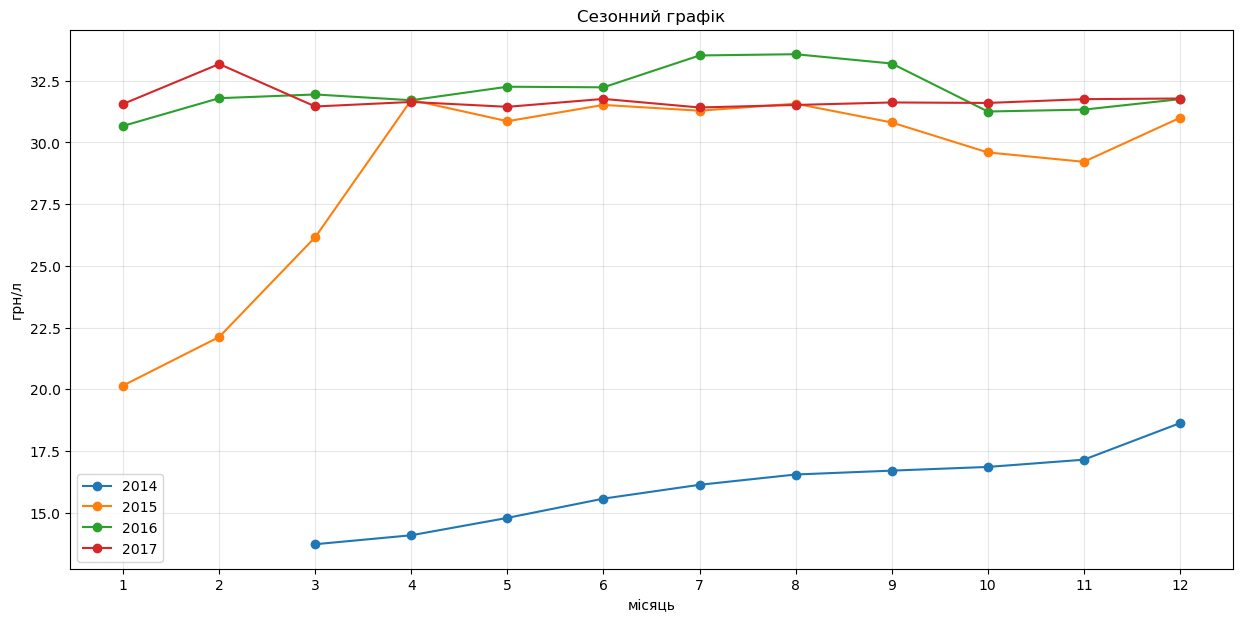

In [286]:
fig, ax = plt.subplots(figsize=(15, 7))
for yr, g in y.groupby(y.index.year):
    ax.plot(g.index.month, g.values, marker='o', label=str(yr))
ax.set_xticks(range(1, 13)); ax.set_xlabel('місяць'); ax.set_ylabel('грн/л')
ax.set_title('Сезонний графік'); ax.legend(); ax.grid(alpha=.3)
plt.show()

**Пояснення** Третій графік — сезонний: по горизонталі місяці року, кожен рік — окрема лінія. Обрано такий формат, бо так можна порівняти, як поводиться ціна в тому самому місяці у різні роки. Шкала звичайна, у гривнях, щоб лінії різних років можна було порівнювати за висотою. Якби в ряді була сезонність, лінії мали б схожу форму, наприклад піки чи спади в тих самих місяцях.

Питання, на яке відповідає графік: `чи спостерігється сезонність?`

**Висновок до завдання 3:**

**Несподівана знахідка:** Ціна олії не зростала поступово протягом усього періоду. Насправді майже весь ріст  стався всього за п'ять місяців - з грудня 2014 по квітень 2015. Після цього ціна майже не змінювалась: протягом 2016–2017 років вона трималась на рівні 31–32 грн.

## Завдання 4. Розкладання на складові

Розкладіть ряд на тренд, сезонну складову та залишок методом STL із періодом 12.

**У звіті наведіть:**
1. чотирипанельний графік розкладання;
2. числові значення сили сезонності $F_S$ та сили тренду $F_T$;
3. **висновок: чи є у вашому ряді сезонність**, із посиланням на порогове значення.

> 💡 **Підказка.** STL поверне сезонну складову завжди. Ваше завдання — вирішити, чи вона означає щось, а не чи вона є.

In [287]:
from statsmodels.tsa.seasonal import STL
import matplotlib.dates as mdates

def strength(r):
    T, S, R = r.trend, r.seasonal, r.resid
    F_S = max(0, 1 - R.var() / (S + R).var())
    F_T = max(0, 1 - R.var() / (T + R).var())
    return F_S, F_T

stl = STL(y, period=12, robust=True).fit()

parts = [(y, 'Вихідний ряд', 'грн/л'),
         (stl.trend, 'Тренд', 'грн/л'),
         (stl.seasonal, 'Сезонна складова', 'відхилення, грн'),
         (stl.resid, 'Залишок', 'відхилення, грн')]


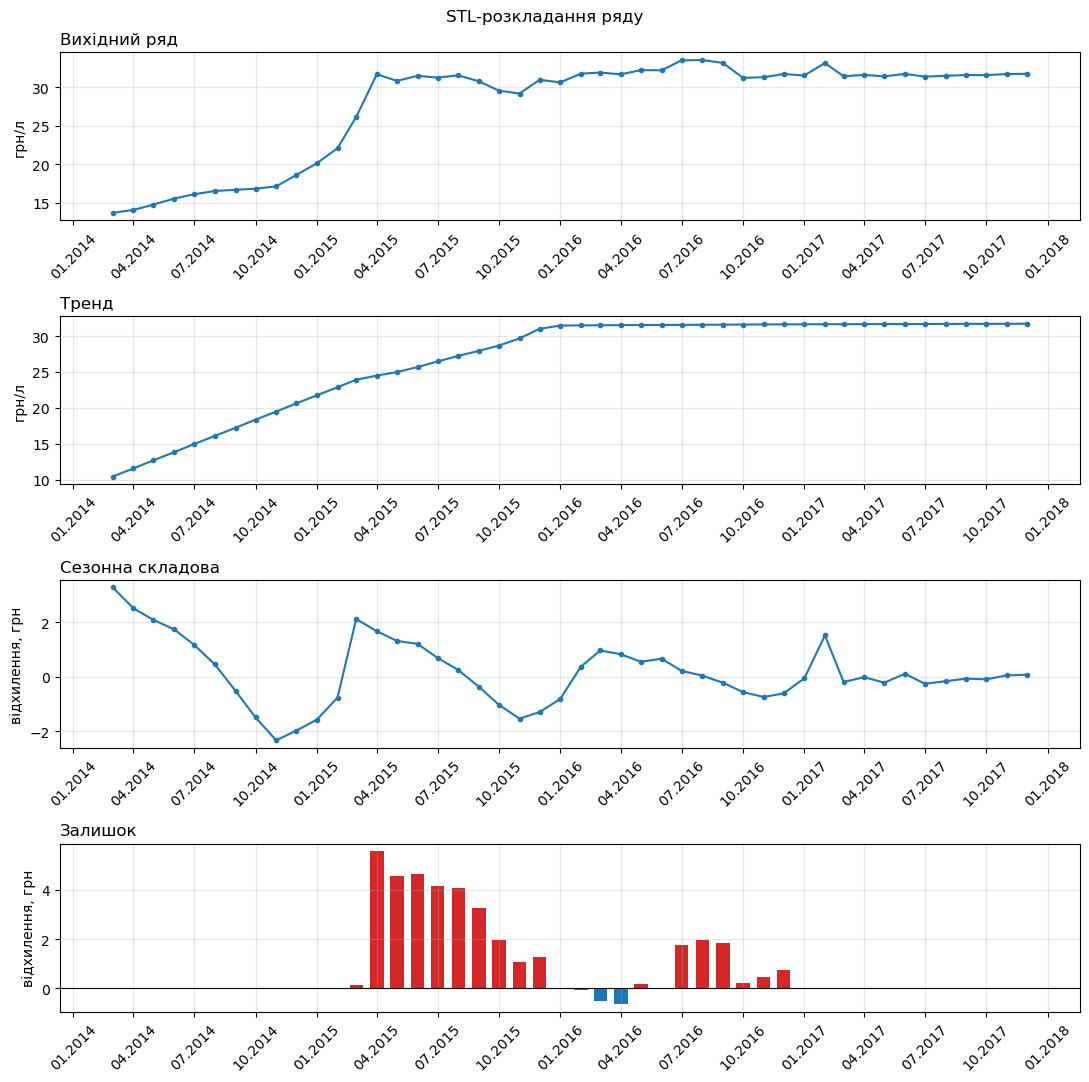

In [288]:
fig, axes = plt.subplots(4, 1, figsize=(11, 11), sharex=True)
for ax, (s, title, unit) in zip(axes, parts):
    if title == 'Залишок':
        ax.bar(s.index, s.values, width=20,
               color=['tab:red' if v > 0 else 'tab:blue' for v in s.values])
        ax.axhline(0, color='black', lw=0.8)
    else:
        ax.plot(s.index, s.values, marker='o', ms=3)

    ax.set_title(title, loc='left'); ax.set_ylabel(unit); ax.grid(alpha=.3)
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%m.%Y'))
    ax.tick_params(axis='x', labelbottom=True, labelrotation=45)
fig.suptitle('STL-розкладання ряду')
plt.tight_layout(); plt.show()

In [289]:
F_S, F_T = strength(stl)
print(f'F_S(сила сезонності)={F_S:.3f}, F_T(сила тренду)= {F_T:.3f}')

print('\nТаблиця сезонності по місяцях для кожного року')
print('-'*100)
S = stl.seasonal
season_table = pd.DataFrame({'рік': S.index.year, 'місяць': S.index.month, 'S': S.values}).pivot_table(index='рік', columns='місяць', values='S').round(2)
print(season_table)

F_S(сила сезонності)=0.445, F_T(сила тренду)= 0.951

Таблиця сезонності по місяцях для кожного року
----------------------------------------------------------------------------------------------------
місяць    1     2     3     4     5     6     7     8     9     10    11    12
рік                                                                           
2014     NaN   NaN  3.27  2.50  2.08  1.73  1.16  0.45 -0.52 -1.50 -2.34 -1.99
2015   -1.58 -0.77  2.11  1.66  1.31  1.20  0.68  0.24 -0.38 -1.04 -1.55 -1.30
2016   -0.82  0.36  0.96  0.82  0.54  0.66  0.21  0.03 -0.23 -0.57 -0.75 -0.62
2017   -0.07  1.51 -0.20 -0.02 -0.23  0.10 -0.27 -0.17 -0.08 -0.10  0.04  0.07


**Висновок до завдання 4:** F_S = 0.44, F_T = 0.951.
Посилаючись на 4 лекцію:
- якщо F_S < 0.3 - сезонності немає
- якщо 0.3 <= F_S =< 0.5 - сезонність середня
- якщо F_S > 0.5 - сезонність сильна

**Тренд.** F_T = 0.951 - тренд дуже сильний: ціна зросла з ≈14 до ≈32 грн і після 2015 року трималась на новому рівні.

**Сезонність.** Формально F_S = 0.445 потрапляє в зону середньої сезонності. 

Проте перевірка показує, що сезонний малюнок не повторюється з року в рік:
| Рік | Пік (місяць) | Мінімум (місяць) | Розмах, грн |
|---|---|---|---|
| 2014 | березень (+3.27) | листопад (−2.34) | 5.61 |
| 2015 | березень (+2.11) | січень (−1.58) | 3.70 |
| 2016 | березень (+0.96) | січень (−0.82) | 1.78 |
| 2017 | лютий (+1.51) | липень (−0.27) | 1.78 |

Сезонна складова у 2014–2016 роках має однакову форму (пік у березні, мінімум у листопаді–січні), але її амплітуда стрімко зменшується: розмах 5.61 грн у 2014 році, 3.70 — у 2015, 1.78 — у 2016. 

У 2017 році хвиля відсутня: майже всі значення сезонної складової близькі до нуля (від −0.27 до +0.10 грн), тобто жоден місяць не був помітно дорожчим чи дешевшим за інші. Виняток — лютий (+1.51 грн), коли ціна разово підскочила, але це одиничний випадок, а не повторювана хвиля.

Отже, підсумовуючи: сезонності в моєму ряді немає.

## Завдання 5. Стаціонарність

Побудуйте ACF і PACF вихідного ряду та його першої різниці. Застосуйте тести ADF і KPSS до обох.

**У звіті наведіть:**
1. графіки ACF і PACF до та після диференціювання;
2. таблицю з $p$-значеннями обох тестів для обох рядів;
3. висновок про стаціонарність **із зазначенням, узгоджуються тести між собою чи ні**;
4. якщо не узгоджуються — ваше пояснення, чому.

> 💡 **Підказка.** Нульові гіпотези ADF і KPSS протилежні. Перш ніж писати висновок, перевірте, що ви не переплутали напрямок.

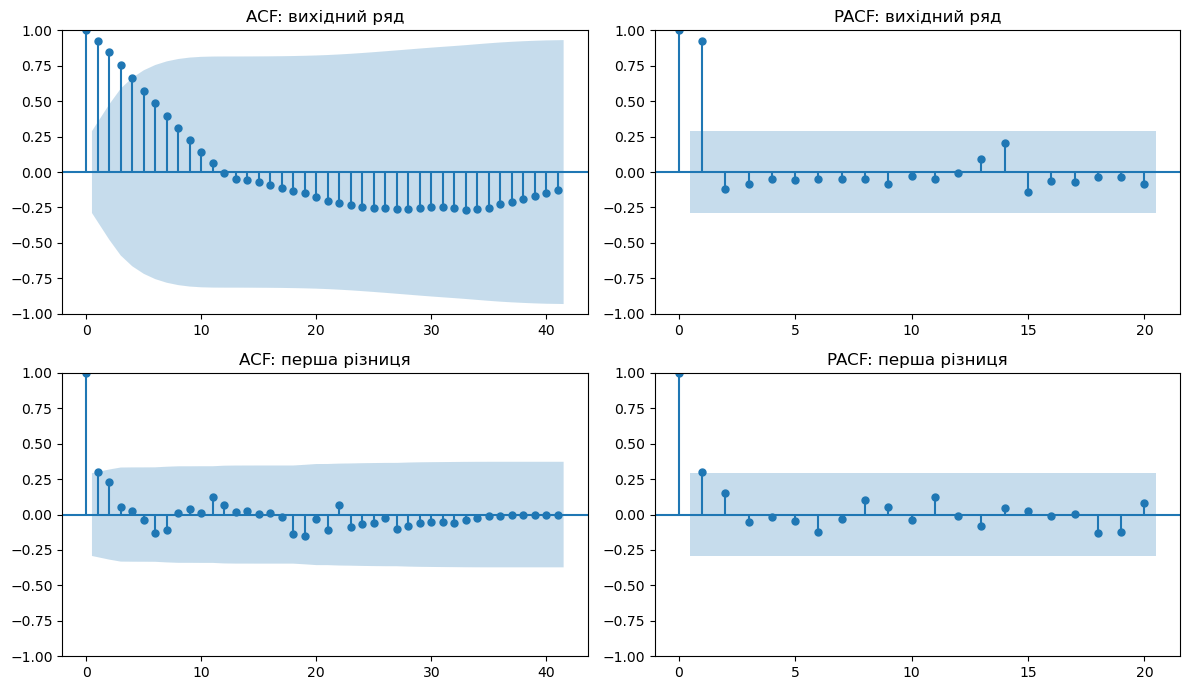

In [290]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf

dy = y.diff().dropna()

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
plot_acf(y,   lags=41, ax=axes[0, 0], title='ACF: вихідний ряд')
plot_pacf(y,  lags=20, ax=axes[0, 1], title='PACF: вихідний ряд', method='ywm')
plot_acf(dy,  lags=41, ax=axes[1, 0], title='ACF: перша різниця')
plot_pacf(dy, lags=20, ax=axes[1, 1], title='PACF: перша різниця', method='ywm')
plt.tight_layout();
plt.show()

In [291]:
rows = []
for name, s in [('вихідний', y), ('перша різниця', dy)]:
    p_adf  = adfuller(s, autolag='AIC')[1]
    p_kpss = kpss(s, regression='c', nlags='auto')[1]
    rows.append({
        'ряд': name,
        'p ADF': p_adf,
        'p KPSS': p_kpss,
        'висновок ADF':  'стаціонарний' if p_adf < .05 else 'нестаціонарний',
        'висновок KPSS': 'нестаціонарний' if p_kpss < .05 else 'стаціонарний',
    })
    
display(pd.DataFrame(rows).set_index('ряд').round(4))

C:\Users\payar\AppData\Local\Temp\ipykernel_20012\3977901254.py:4: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  p_kpss = kpss(s, regression='c', nlags='auto')[1]
C:\Users\payar\AppData\Local\Temp\ipykernel_20012\3977901254.py:4: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  p_kpss = kpss(s, regression='c', nlags='auto')[1]


,p ADF,p KPSS,висновок ADF,висновок KPSS
ряд,,,,
вихідний,0.1603,0.01,нестаціонарний,нестаціонарний
перша різниця,0.0001,0.10,стаціонарний,стаціонарний


**Висновок до завдання 5:** Тести узгодились: вихідний ряд - обидва тести сказали, що ряд нестаціонарний, перша різниця - ряд стаціонарний.

## Завдання 6. Базисні прогнози та ретроспективна перевірка

Побудуйте **чотири** базисні прогнози: наївний, сезонний наївний, середнє та дрейф.
Оцініть їх **ретроспективною перевіркою з рухомим початком**: **7 фолдів по 3 кроки**,
навчальна частина розширюється.

**У звіті наведіть:**
1. таблицю MAE, RMSE і MAPE для всіх чотирьох базисів;
2. який базис виявився найкращим і **чому саме він** — поясніть через властивості вашого ряду;
3. для порівняння: ту саму оцінку, зроблену звичайним випадковим поділом 75/25, і **у скільки разів** вона відрізняється.

> 💡 **Підказка.** Кількість фолдів і кроків задана жорстко — у Частині 2 вона має збігтися з налаштуваннями Orange.

In [292]:
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, root_mean_squared_error

def metrics(a, f):
    return {
        'MAE':     mean_absolute_error(a, f),
        'RMSE':    root_mean_squared_error(a, f),
        'MAPE': mean_absolute_percentage_error(a, f),
    }

In [293]:
def f_naive(tr, h):  return np.repeat(tr.iloc[-1], h)
def f_snaive(tr, h): return np.array([tr.iloc[-12 + (i % 12)] for i in range(h)])
def f_mean(tr, h):   return np.repeat(tr.mean(), h)
def f_drift(tr, h):
    slope = (tr.iloc[-1] - tr.iloc[0]) / (len(tr) - 1)
    return tr.iloc[-1] + slope * np.arange(1, h + 1)

BASES = {'naive': f_naive, 'seasonal naive': f_snaive, 'mean': f_mean, 'drift': f_drift}

In [294]:
# ретроспективна перевірка з рухомим початком
from sklearn.model_selection import TimeSeriesSplit
tscv = TimeSeriesSplit(n_splits=7, test_size=3)

def evaluate_tscv(fc):
    act, pred = [], []
    for tr_idx, te_idx in tscv.split(y):
        act  += list(y.iloc[te_idx])                         # справжні значення
        pred += list(fc(y.iloc[tr_idx], len(te_idx)))        # прогноз лише за минулим
    return metrics(act, pred)

In [295]:
res = pd.DataFrame({name: evaluate_tscv(fc) for name, fc in BASES.items()}).T
print('Ретроспективний поділ з рухомим початком:')
display(res.round(3))

Ретроспективний поділ з рухомим початком:


,MAE,RMSE,MAPE
naive,0.626,0.886,0.019
seasonal naive,1.139,1.384,0.035
mean,5.981,6.190,0.186
drift,1.254,1.533,0.039


In [296]:
from sklearn.model_selection import train_test_split

def random_split(seed):
    tr_idx, te_idx = train_test_split(np.arange(len(y)), test_size=0.25, random_state=seed)
    return np.sort(tr_idx), np.sort(te_idx)

def predict_point(fc, t, tr_idx):
    if fc is f_mean:
        return y.iloc[tr_idx].mean()
    if fc is f_snaive:
        return y.iloc[t - 12] if (t - 12) in tr_idx else None 
    past = y.iloc[tr_idx[tr_idx < t]]
    return fc(past, 1)[0] if len(past) >= 2 else None

def evaluate_random(fc, seed):
    tr_idx, te_idx = random_split(seed)
    act, pred = [], []
    for t in te_idx:
        p_ = predict_point(fc, t, tr_idx)
        if p_ is None:
            continue # пропускаємо місяць без прогнозу
        act.append(y.iloc[t]); pred.append(p_)
    return metrics(act, pred)


rnd = pd.DataFrame({name: pd.DataFrame([evaluate_random(fc, s) for s in range(200)]).mean() for name, fc in BASES.items()}).T

print('Випадковий поділ 75/25:')
display(rnd.round(3))

Випадковий поділ 75/25:


,MAE,RMSE,MAPE
naive,0.991,1.520,0.037
seasonal naive,6.013,8.267,0.195
mean,5.838,6.720,0.272
drift,1.216,1.596,0.043


In [297]:
print('\nУ скільки разів похибка випадкового поділу відрізняється від рухомого початку:')
print((rnd / res).round(2))


У скільки разів похибка випадкового поділу відрізняється від рухомого початку:
                 MAE  RMSE  MAPE
naive           1.58  1.71  1.89
seasonal naive  5.28  5.97  5.50
mean            0.98  1.09  1.46
drift           0.97  1.04  1.08


**Висновок до завдання 6:** **Висновок до завдання 6:**

Базисні прогнози оцінено ретроспективною перевіркою з рухомим початком. 
**Найкращий базис — наївний** за всіма трьома метриками:
| Базис | MAE, грн | RMSE, грн | MAPE |
|---|---|---|---|
| наївний | 0.626 | 0.886 | 0.019 |
| сезонний наївний | 1.139 | 1.384 | 0.035 |
| середнє | 5.981 | 6.190 | 0.186 |
| дрейф | 1.254 | 1.533 | 0.039 |

Базисні прогнози оцінено рандомним розділенням 75/25. 
**Найкращий базис — наївний** за всіма трьома метриками:

| Базис | MAE, грн | RMSE, грн | MAPE |
|---|---|---|---|
| наївний | 0.991 | 1.520 | 0.037 |
| сезонний наївний | 6.013 | 8.267 | 0.195 |
| середнє | 5.838 | 6.720 | 0.272 |
| дрейф | 1.216 | 1.596 | 0.043 |

**У скільки разів похибка випадкового поділу відрізняється від рухомого початку:**
| Базис | MAE | RMSE | MAPE |
|---|---|---|---|
| наївний | у 1.58 раза | у 1.71 раза | у 1.89 раза |
| сезонний наївний | у 5.28 раза | у 5.97 раза | у 5.50 раза |
| середнє | у 0.98 раза | у 1.09 раза | у 1.46 раза |
| дрейф | у 0.97 раза | у 1.04 раза | у 1.08 раза |

Отже, випадковий поділ дає оцінку, яка не відповідає реальній задачі прогнозування: він змішує періоди й допускає витік інформації з майбутнього. Для часових рядів коректна лише перевірка з рухомим початком.

## Завдання 7. Модель ARIMA

Побудуйте модель ARIMA і оцініть її **на тих самих 7 фолдах по 3 кроки**.

Обов'язково використайте порядок **(1, 1, 1)** — саме його ви відтворюватимете в Orange.
Додатково визначте, який порядок $(p, d, q)$ ви обрали б **за виглядом ACF і PACF** із завдання 5.

**У звіті наведіть:**
1. MAE, RMSE і MAPE моделі ARIMA(1,1,1) на рухомому початку;
2. обґрунтування порядку, який ви обрали б самостійно, з посиланням на конкретні лаги;
3. **порівняння з найкращим базисом із завдання 6** — і прямий висновок, чи має ця модель право на існування;
4. графік залишків моделі та висновок, чи лишилася в них структура.

> 💡 **Підказка.** Якщо ARIMA програла базису — це законний результат, а не помилка. Напишіть про це прямо.

In [298]:
from statsmodels.tsa.arima.model import ARIMA

def f_arima(order):
    def fc(tr, h):
        return ARIMA(tr, order=order).fit().forecast(h).values
    return fc

In [299]:
cmp = pd.DataFrame({
    'наївний базис': res.loc['naive'],
    'ARIMA(1,1,1)': evaluate_tscv(f_arima((1, 1, 1)))
}).T

print('MAE, RMSE і MAPE моделі ARIMA(1,1,1) та наївного базису на рухомому початку:')
display(cmp.round(3))

ratio = (cmp.loc['ARIMA(1,1,1)'] / cmp.loc['наївний базис']).round(2)
print('У скільки разів похибка ARIMA(1,1,1) відрізняється від наївного:')
display(ratio.to_frame('ARIMA(1,1,1) / наївний').T)


MAE, RMSE і MAPE моделі ARIMA(1,1,1) та наївного базису на рухомому початку:


,MAE,RMSE,MAPE
наївний базис,0.626,0.886,0.019
"ARIMA(1,1,1)",0.684,0.877,0.021


У скільки разів похибка ARIMA(1,1,1) відрізняється від наївного:


,MAE,RMSE,MAPE
"ARIMA(1,1,1) / наївний",1.09,0.99,1.1


**Пояснення**

p - авторегресія (AR).  Значення 1, оскільки, на графіку PACF останній стовпчик, що виходить за межі довірчої зони стоїть на 1.

d - інтегрованість (I). Значення 1, оскільки, за тестами ADF та KPSS достатньо було зробити 1 різницю щоб ряд став стаціонарним.

q - ковзне середнє (MA). Значення 1, оскільки, на графіку ACF останній стовпчик, що виходить за межі довірчої зони стоїть на 1.

Змішана модель, бо p = q = 1. Ризик: перенавчання моделі, бо виникає надмірність параметрів, які описують одне і теж.

In [300]:
from statsmodels.stats.diagnostic import acorr_ljungbox

fit = ARIMA(y, order=(1, 1, 1)).fit()
resid = fit.resid.iloc[1:] # перший залишок - сам рівень ряду, відкидаємо

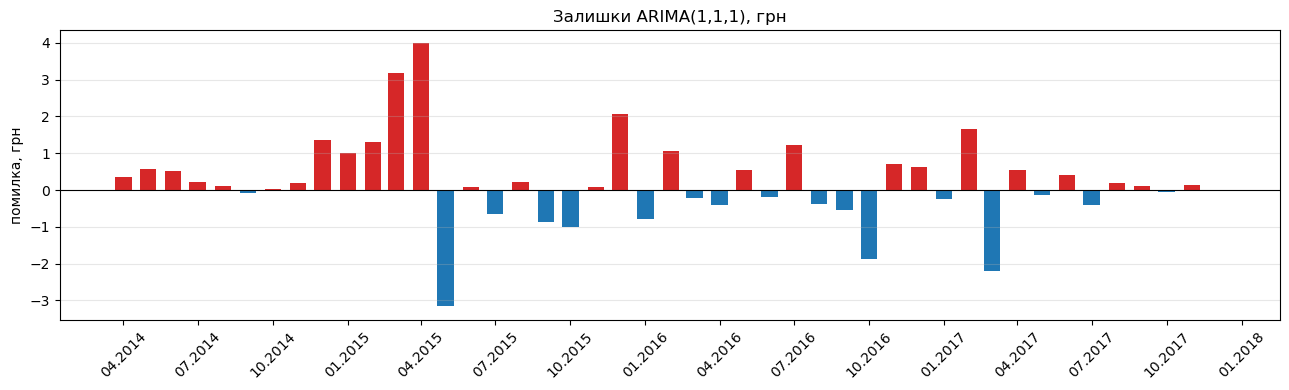

In [301]:
import matplotlib.dates as mdates

fig, ax = plt.subplots(figsize=(13, 4))
ax.bar(resid.index, resid.values, width=20,
       color=['tab:red' if v > 0 else 'tab:blue' for v in resid.values])
ax.axhline(0, color='black', lw=0.8)
ax.set_title('Залишки ARIMA(1,1,1), грн')
ax.set_ylabel('помилка, грн'); ax.grid(alpha=.3, axis='y')
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%m.%Y'))
ax.tick_params(axis='x', rotation=45)
plt.tight_layout(); plt.show()

**Пояснення.** З графіка видно, що помилки прогнозу моделі хаотичні: вони коливаються навколо нуля, не утворюють регулярних хвиль чи циклічних піків і не зростають або спадають стабільно з часом. Отже, систематичної закономірності, яку модель могла б врахувати, у залишках не лишилося.

**Висновок до завдання 7:**

**1. Похибки на рухомому початку:**

| Модель | MAE | RMSE | MAPE|
|---|---|---|---|
| наївний базис | 0.626 | 0.886 | 0.019 |
| ARIMA(1,1,1) | 0.684 | 0.877 | 0.021 |

**2. Порядок моделі за ACF і PACF:**
- $p = 1$ — на PACF першої різниці останній стовпчик за межами довірчої зони стоїть на лагу 1;
- $d = 1$ — за тестами ADF і KPSS однієї різниці достатньо, щоб ряд став стаціонарним;
- $q = 1$ — на ACF першої різниці останній стовпчик за межами довірчої зони стоїть на лагу 1.

Отже, змішана модель ARIMA(1,1,1). Ризик — надмірність параметрів: AR- і MA-частини можуть описувати одну й ту саму слабку залежність на лагу 1.

**3. Порівняння з найкращим базисом.** ARIMA(1,1,1) гірша за наївний прогноз за MAE (у 1.09 раза) і MAPE (у 1.1 раза), а за RMSE практично однакова (0.99). Модель не перевершила найпростіший базис, тому для цього ряду вона не має практичного права на існування.

**4. Залишки.** Помилки прогнозу хаотичні: вони коливаються навколо нуля, не утворюють регулярних хвиль чи циклічних піків і не зростають або спадають стабільно з часом. Систематичної закономірності, яку модель могла б врахувати, у залишках не лишилося.

## Завдання 8. Точка зміни режиму

Знайдіть у своєму ряді точку, після якої змінюється **рівень** ряду.
Скористайтеся скануванням: для кожної кандидатної дати порівняйте середні до і після
та оберіть дату з найбільшою t-статистикою.

**У звіті наведіть:**
1. графік ряду з позначеною знайденою датою;
2. дату, значення t-статистики, середні рівні до і після;
3. **чи є ця точка значущою** — і якщо ні, так і напишіть;
4. чим знайдена точка відрізняється від звичайного сезонного сплеску у вашому ряді.

> 💡 **Підказка.** Не плутайте зсув рівня з сезонним піком. Якщо «аномалії» повторюються щороку в ті самі місяці — це сезон.

In [302]:
from scipy import stats

MIN_SEG = 6

def scan(series):
    out = []
    for k in range(MIN_SEG, len(series) - MIN_SEG + 1):
        before, after = series.iloc[:k], series.iloc[k:]
        t, p_ = stats.ttest_ind(after, before, equal_var=False)
        out.append((series.index[k], t, p_, before.mean(), after.mean()))
    return pd.DataFrame(out, columns=['date', 't', 'p', 'mean_before', 'mean_after']).set_index('date')

sc = scan(y)
best = sc['t'].abs().idxmax(); b = sc.loc[best]
print(f'Точка зміни: {best:%Y-%m}, t = {b.t:.2f}, p = {b.p:.1e}')
print(f'Середнє до: {b.mean_before:.2f} грн, \nСереднє після: {b.mean_after:.2f} грн')


Точка зміни: 2015-01, t = 22.67, p = 3.8e-19
Середнє до: 16.02 грн, 
Середнє після: 30.89 грн


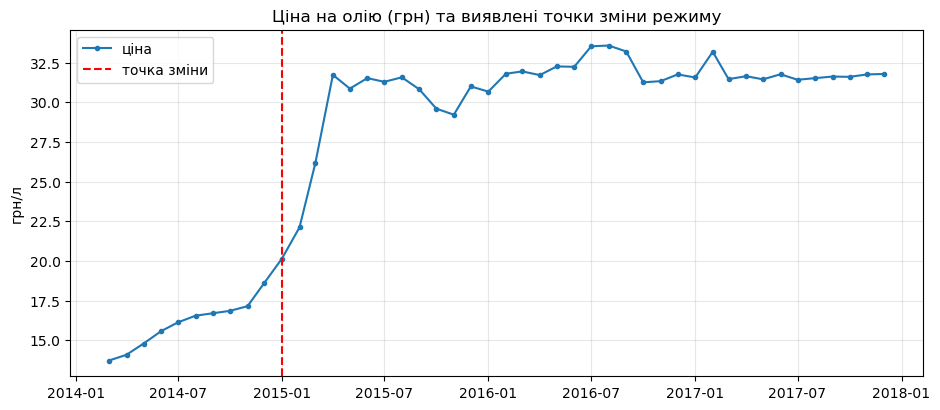

In [303]:

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(y.index, y.values, marker='o', ms=3, label='ціна')
ax.axvline(best, color='red', ls='--', label=f'точка зміни')
ax.set_ylabel('грн/л'); ax.set_title(f'Ціна на олію (грн) та виявлені точки зміни режиму')
ax.grid(alpha=.3) 
ax.legend()
plt.show()

**Висновок до завдання 8:**
Скануванням за t-статистикою знайдено точку зміни рівня - **січень 2015 року**.

| Показник | Значення |
|---|---|
| t-статистика | 22.67 |
| середнє до | 16.02 грн |
| середнє після | 30.89 грн |

**Значущість.** Точка значуща, бо значення p <= 0.05.

**Зсув рівня, а не сезон.** Різкий ріст ціни навесні відбувся лише один раз. Після стрибка ціна не повернулась назад і трималась на новому рівні до кінця 2017 року. Сезонний сплеск повторювався б щороку в ті самі місяці й зникав би.


## Завдання 9. Рецензія на чужий аналіз

Відкрийте `ЛР4_помилковий_аналіз.ipynb`. Це звіт, зроблений на іншому ряді з того самого набору.
Він виконується без помилок і виглядає переконливо, але містить **методологічні помилки**.

**У звіті наведіть:**
1. перелік знайдених помилок — для кожної вкажіть номер клітинки, суть помилки й **чим вона небезпечна**;
2. для трьох найсерйозніших — як саме їх виправити.

> 💡 **Підказка.** Помилок щонайменше вісім. Шукайте не синтаксис, а порушення принципів роботи з часовими рядами.

**Висновок до завдання 9:**

Зошит аналізує ціни на гречку у Вінницькій області. Знайдено 10 помилок:

| Розділ | Суть помилки | Чим небезпечна |
|---|---|---|
| 1 | Автор шукає пропуски у ряді, але пропущений місяць там просто відсутній — порожньої клітинки немає. Тому перевірка каже «пропусків немає», хоча один місяць загублено.| Усі розрахунки, де важливо «місяць тому» чи «рік тому», зсуваються, бо програма не знає про пропущений місяць. |
| 2 | Автор порівнює лише першу і останню ціну й робить висновок, що людям стало важче купувати. | Усе, що було між ними (ціна злетіла, а потім упала), зникає. До того ж висновок про купівельну спроможність не можна робити лише з цін: треба знати, як змінювались зарплати й інфляція. |
| 3 | Автор порівнює похибки двох товарів у гривнях| Для дорогого товару та сама похибка в гривнях — це дрібниця, а для дешевого — багато. Висновок виходить навпаки. Порівнювати треба у відсотках. |
| 4 | Неправильно обрахована кореляція для часового ряду. | У часових рядах звичайна кореляція Пірсона часто не працює належним чином через наявність трендів, сезонності та залежності даних від часу (автокореляції). |
| 5 | Автор вважає ряд сезонним, бо метод STL намалював сезонну складову. | STL повертає сезонну складову завжди. Сила сезонності F_S = 0.26 < 0.3, місяць піку щороку різний. Сезонності немає. |
| 6 | ADF p = 0.233 трактується як «ряд стаціонарний», хоча H₀ тесту ADF — нестаціонарність. Потім ряд «для надійності» диференціюють двічі, не перевіривши першу різницю й не застосувавши KPSS. | Висновок перевернутий, а зайве диференціювання псує модель. |
| 7 | У тексті поріг «два стандартні відхилення» вказано, а в коді 1.3σ. Z-оцінка рахується на вихідному ряді з трендом. | Аномаліями стають просто періоди, коли ціна була загалом низькою чи високою, а не справді незвичайні місяці. Аномалії треба шукати після того, як прибрано тренд. |
| 8 | Модель перевіряється випадковим поділом даних, тож вона «бачить» майбутнє під час навчання. Тестові значення ще й посортовано, тож прогноз порівнюється не з тими місяцями. Базового наївного прогнозу для порівняння немає. | Витік інформації з майбутнього і порівняння прогнозу з неправильними значеннями нічого не означає. Порівняння з сезонним наївним некоректне (різні дані).|
| 9 | Для прогнозу використано ARIMA(2,2,1), а перевірялась ARIMA(1,1,1). Висновок «ціна продовжить зростати» неправильна, на графіку спадає. | Модель, якою прогнозують, ніколи не перевірялась. Висновок суперечить власному результату.|
| 10 | Стовпчикова діаграма починається не з нуля, і показано лише пів року. Показано лише перше півріччя 2016 року. | Обрізана вісь візуально перебільшує зміни. А вибране вікно приховує, що одразу після показаного зростання ціна впала. |


**Як виправити три найсерйозніші помилки**

**1. Перевірка моделі (розділ 8).**
Проблема: модель перевіряється випадковим поділом, тому під час навчання «бачить» майбутнє, а прогноз порівнюється не з тими місяцями.
Виправлення: перевіряти модель лише так, як її використовують у житті, — навчати на минулому і прогнозувати майбутнє. Для цього замість `train_test_split` використати ретроспективну перевірку з рухомим початком: модель кілька разів навчається на даних до певного місяця і прогнозує наступні 3 місяці. На тих самих фолдах порахувати похибки найпростіших прогнозів (наївного, сезонного наївного, середнього, дрейфу) і вважати модель корисною лише тоді, коли вона перевершує найкращий із них.

**2. Стаціонарність (розділ 6).**
Проблема: результат тесту ADF прочитано навпаки, а різницю взято двічі без перевірки.
Виправлення: пам'ятати, що в тесті ADF нульова гіпотеза — «ряд нестаціонарний», тому велике p-значення означає саме нестаціонарність. Для надійності додати тест KPSS, у якого нульова гіпотеза протилежна. Спершу перевірити обома тестами першу різницю, і лише якщо вона не стаціонарна, брати другу. Знайдену кількість різниць використовувати в тій самій моделі, яку перевіряють і якою потім прогнозують.

**3. Сезонність (розділ 5).**
Проблема: ряд названо сезонним лише тому, що STL намалював сезонну складову.
Виправлення: перевірити, чи сезонна складова щось означає. Порахувати силу сезонності F_S  і порівняти з порогом (нижче 0.3 — сезонності немає). Додатково перевірити, чи пік ціни щороку припадає на той самий місяць. Сезонні моделі використовувати лише тоді, коли сезонність підтверджено.

## Завдання 10. Експорт ряду для Orange

Збережіть підготовлений ряд у файл `ряд_для_orange.csv` **рівно у такому вигляді**:

| Стовпець | Тип | Зміст |
|---|---|---|
| `date` | текст у форматі `РРРР-ММ-ДД` | перше число місяця |
| `price` | число | ціна, пропуск уже заповнений |

Один рядок на місяць, 46 рядків плюс заголовок, роздільник — кома, кодування UTF-8.

**У звіті наведіть:**
1. підтвердження, що файл має 46 рядків даних і не містить порожніх значень.

> 💡 **Підказка.** Формат заданий жорстко: Orange має отримати **точно ті самі** дані, що й Python, інакше порівняння в Частині 2 втрачає сенс.

In [304]:
export = pd.DataFrame({
    'date':  y.index.strftime('%Y-%m-%d'),
    'price': y.values,
})
export.to_csv('ряд_для_orange.csv', index=False, encoding='utf-8')

data = pd.read_csv('ряд_для_orange.csv')
print('Рядків даних:', len(data))
print('Порожніх значень:', data.isna().sum())

Рядків даних: 46
Порожніх значень: date     0
price    0
dtype: int64


**Висновок до завдання 10:**

Експортували дані згідно з вимогами.

---
# ЧАСТИНА 2. Той самий аналіз засобами Orange

*Виконується самостійно.*

Потрібен додаток **Timeseries**: у Orange відкрийте *Options → Add-ons…* і встановіть `Orange3-Timeseries`.

**Головна умова цієї частини:** Orange має отримати **ті самі дані** й **ті самі налаштування перевірки**,
що й Python у Частині 1. Тоді будь-яка розбіжність у числах пояснюється **лише означеннями метрик**,
а не різними даними чи різними моделями. Саме це вам і треба довести.

## Завдання 11. Потік опрацювання даних

Побудуйте в Orange потік:

`File` → `As Timeseries` → `Interpolate` → `Line Chart`

У віджеті **File** завантажте свій `ряд_для_orange.csv`; переконайтеся, що `date` розпізнано
як **time**, а `price` — як **numeric**. У віджеті **As Timeseries** оберіть `date` як часову змінну.

**У звіті наведіть:**
1. знімок екрана з побудованим потоком;
2. знімок `Line Chart` із вашим рядом;
3. підтвердження, що графік у Orange збігається з графіком із завдання 3.

> 💡 **Підказка.** Якщо `date` розпізнано як текст, поверніться до завдання 10 і перевірте формат дати.

**Побудова потоку**

![Screenshot 2026-10-26 193709.png](<attachment:Screenshot 2026-10-26 193709.png>)

**Line Chart**

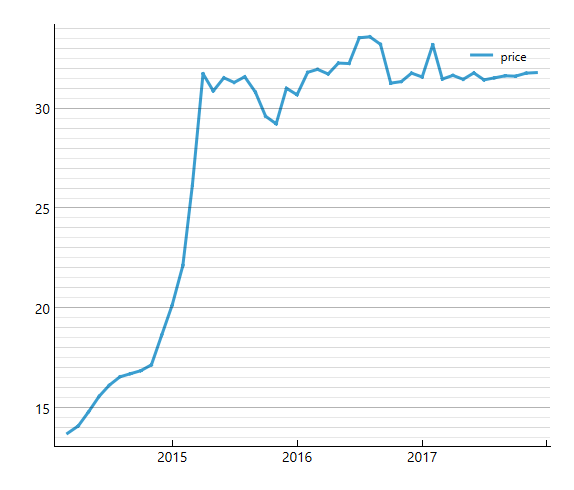

**Графік із Orange та завдання 3**

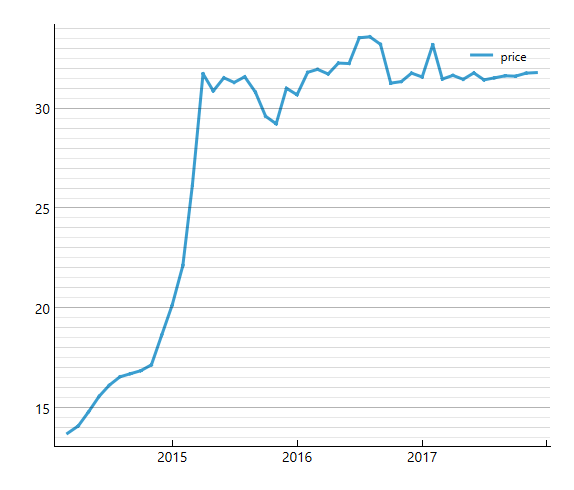    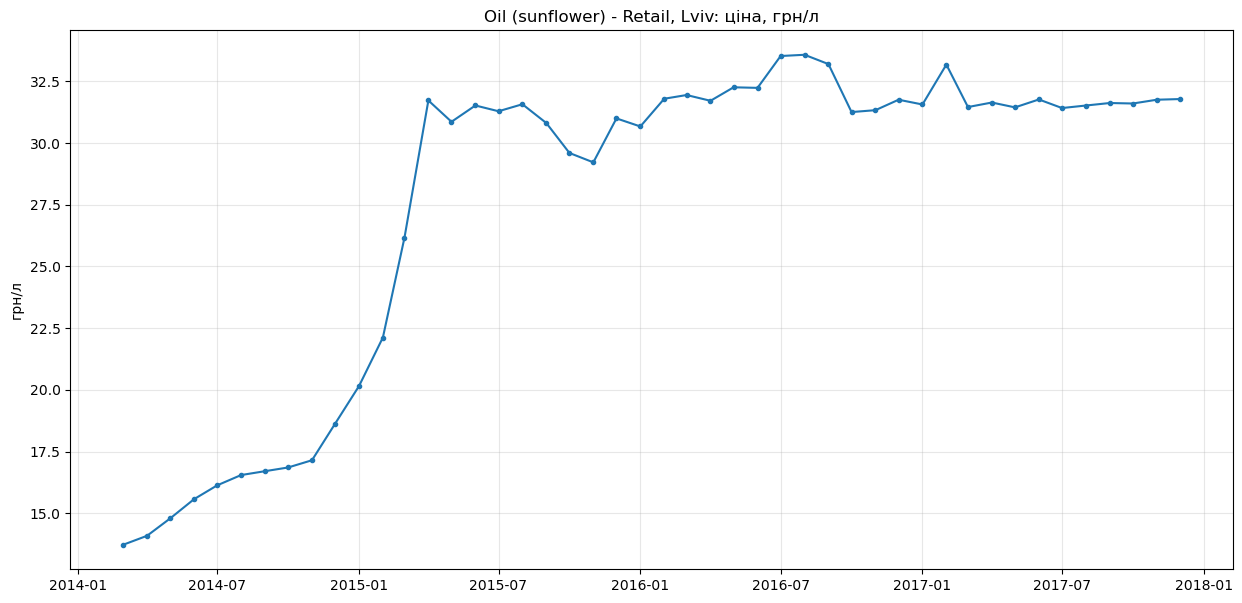


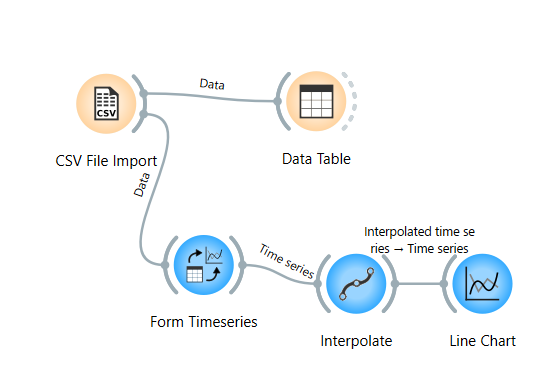

**Висновок до завдання 11:**

Графіки співпадають. Все було зроблено коректно.

## Завдання 12. Автокореляція та диференціювання

Додайте до потоку віджети `Correlogram`, `Difference` та `Seasonal Adjustment`.

**У звіті наведіть:**
1. знімок корелограми;
2. зіставлення з ACF із завдання 5: **чи збігаються висновки** про значущі лаги;
3. знімок сезонно скоригованого ряду та порівняння з сезонною складовою STL із завдання 4.

> 💡 **Підказка.** Orange і statsmodels рахують автокореляцію однаково — якщо картина різна, перевірте, чи однакові дані на вході.

**Побудова**

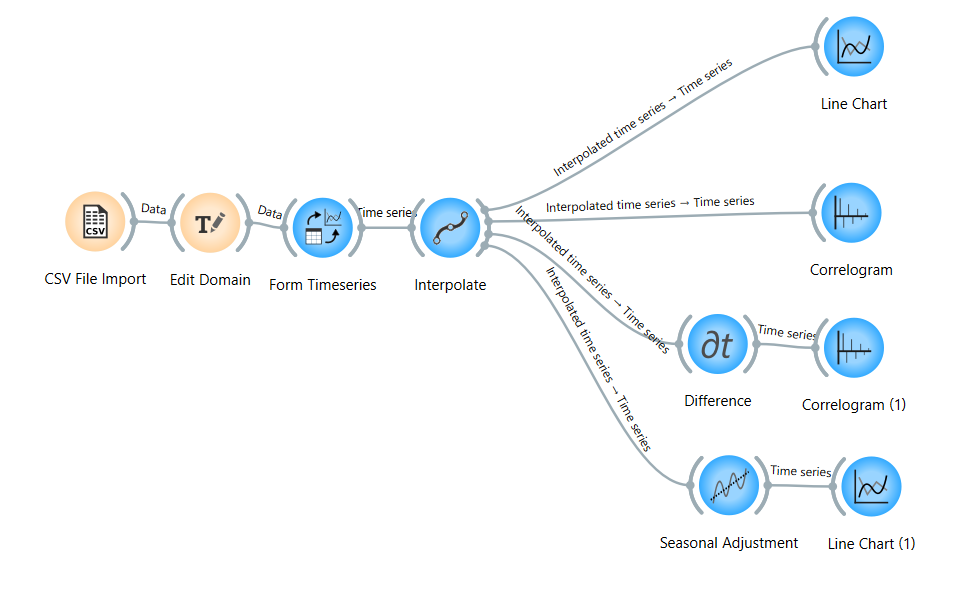


**Зіставлення корелограми з Orange з графіком ACF**

  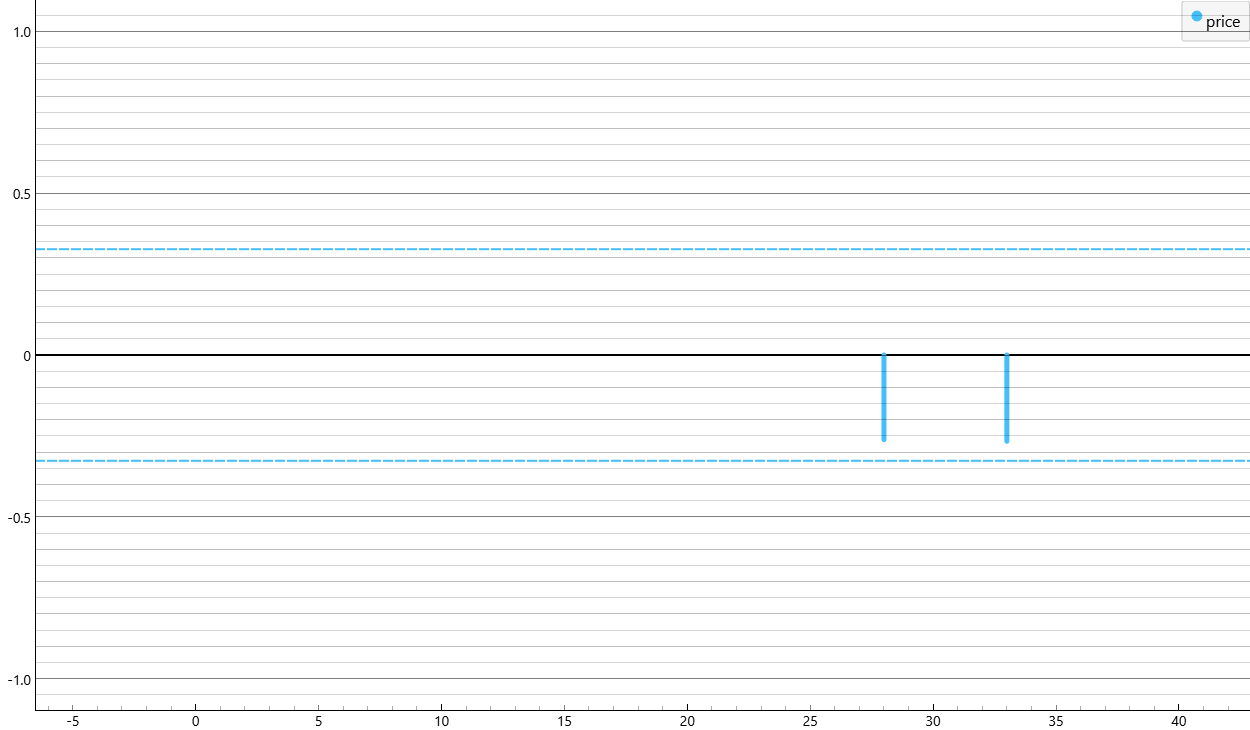   ![Screenshot 2026-10-26 195005.png](<attachment:Screenshot 2026-10-26 195005.png>)
  
  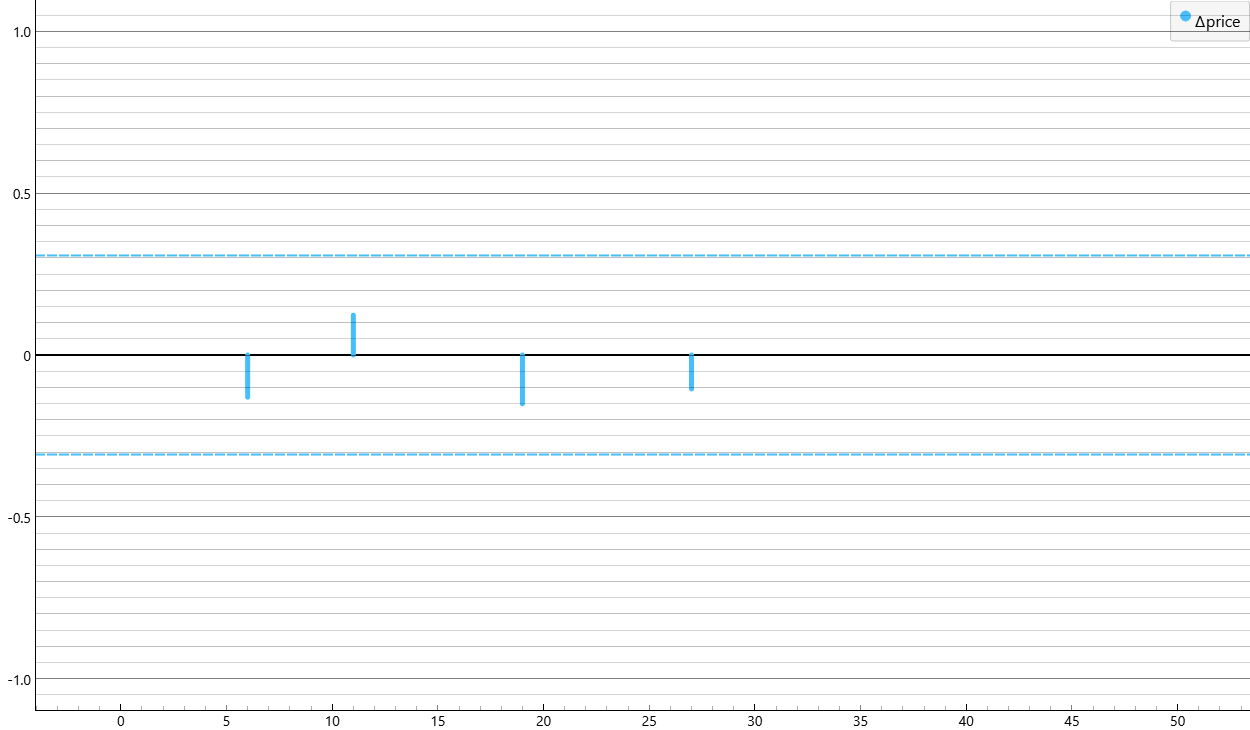  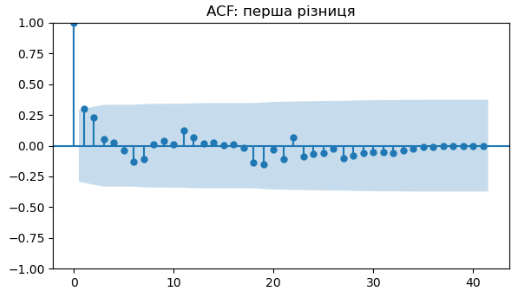

**Сезонно скоригований ряд та сезонно складова STL**

 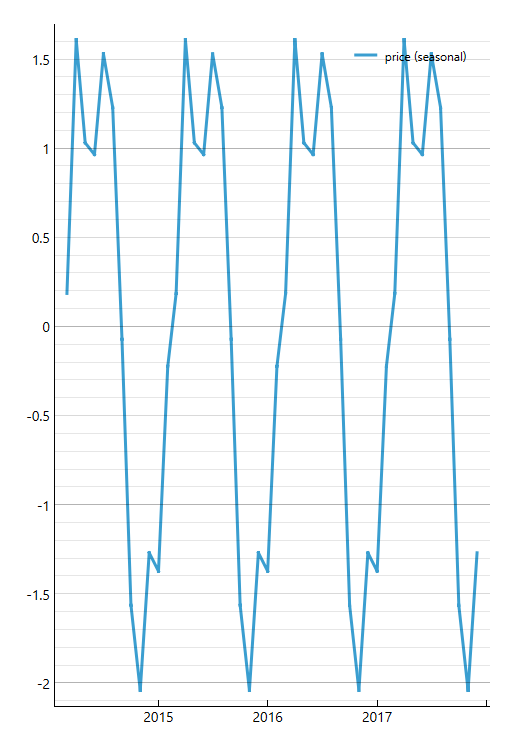  ![Screenshot 2026-10-26 203759.png](<attachment:Screenshot 2026-10-26 203759.png>)
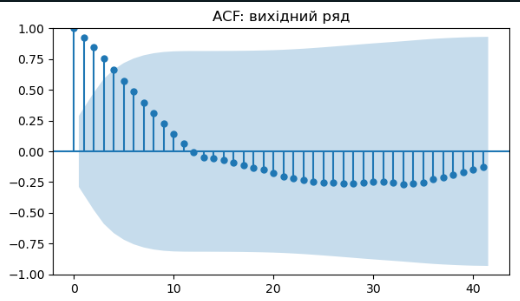
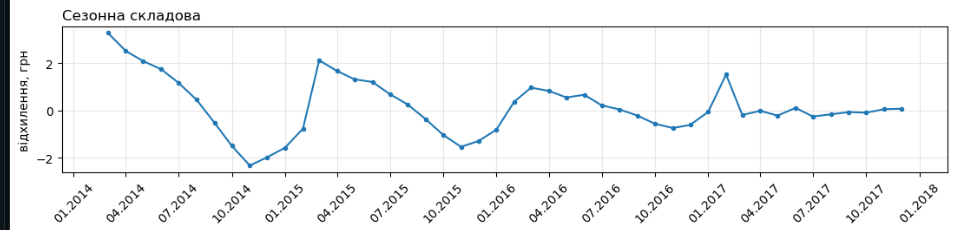

**Висновок до завдання 12:**

**Сезонно скоригований ряд та сезонно складова STL**. Графіки різні, бо методи різні.

**Orange (класичне розкладання)** рахує для кожного місяця одне середнє відхилення від тренду за всі роки і повторює його щороку. Тому хвиля в Orange завжди однакова, навіть якщо сезонності немає.

**STL** дозволяє сезону змінюватися з року в рік. Він групує відхилення від тренду за місяцями (наприклад, усі березні 2014–2017) і проводить через них не одне середнє, а плавну криву методом LOESS, що найбільше враховує сусідні роки. Тому якщо у 2014–2015 роках березневий «пік» був великим, а у 2016–2017 зник, крива STL це покаже — і хвиля згасає.


## Завдання 13. Модель і оцінювання

Додайте `ARIMA Model` з порядком **(1, 1, 1)** та `Model Evaluation`.

У віджеті **Model Evaluation** встановіть **Number of folds = 7** та **Forecast steps = 3**.

**У звіті наведіть:**
1. знімок таблиці Model Evaluation з усіма метриками;
2. **що станеться, якщо лишити типові налаштування** (20 фолдів × 3 кроки) — наведіть повідомлення, яке видасть Orange, і поясніть, звідки воно береться;
3. які саме 7 фолдів перевіряє Orange — тобто на яких відрізках ряду навчається модель.

> 💡 **Підказка.** Orange відмовиться працювати при типових налаштуваннях. Це не збій, а наслідок довжини вашого ряду — порахуйте, якої саме.

**Таблиця Model Evaluation (7 фолдів x 3 роки)**

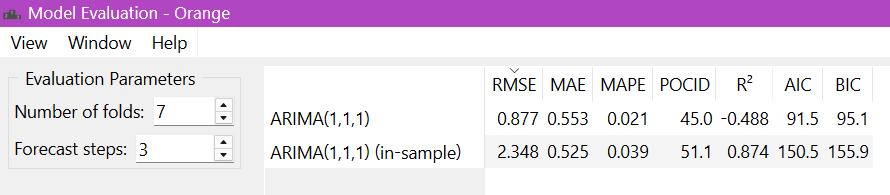

**Таблиця Model Evaluation (20 фолдів x 3 роки)**

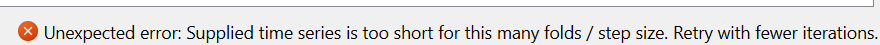

**Відрізки ряду на яких навчалася модель в Orange**

Є припущення, що на тих самих, що й наша модель на Пайтоні, оскільки RMSE однаковий.

| Модель | RMSE |
|---|---|
| ARIMA(1,1,1) (Orange) | 0.877 |
| ARIMA(1,1,1) (Python) | 0.877 |



**Висновок до завдання 13:**

**Чому при 20 фолдах виникає помилка.** Кожен фолд забирає під тест 3 місяці. Для 7 фолдів це 7 × 3 = 21 місяць, для 20 фолдів — уже 20 × 3 = 60 місяців, а весь ряд має лише 46.

RMSE в Orange обрахувався так само як у sklearn. root_mean_square, тому можна вважати, що модель Orange навчалася на тих самих фолдах, що і модель на пайтоні.

## Завдання 14. Чому числа не збігаються

Порівняйте метрики Orange з метриками, які ви отримали в Частині 1 для **тієї самої** моделі
ARIMA(1,1,1) на **тих самих** 7 фолдах.

Для кожної з чотирьох метрик Orange — `RMSE`, `MAE`, `MAPE`, `POCID` — **відтворіть її значення в Python**,
тобто напишіть формулу, за якою Orange отримав саме це число, і переконайтеся, що ваш розрахунок
збігається з таблицею Orange до третього знака.

**У звіті наведіть:**
1. таблицю на чотири рядки: метрика · значення Orange · ваше відтворення в Python · формула;
2. **яка з метрик не відповідає своїй назві** — і чим саме вона відрізняється від того, що зазвичай позначають цією абревіатурою;
3. яка метрика збіглася між середовищами одразу і чому;
4. висновок: що саме треба перевіряти, перш ніж порівнювати числа з двох різних інструментів.

> 💡 **Підказка.** Жодна з розбіжностей не є помилкою Orange. Усі формули відкриті — шукайте їх у вихідному коді додатка Timeseries, файл `functions.py`.

**Source-code з functions.py**

In [305]:
def rmse(true, pred):
    """Root mean squared error"""
    nobs = len(pred)
    return np.sqrt(np.sum((true[-nobs:] - pred) ** 2) / nobs)


def mape(true, pred):
    """Mean absolute percentage error"""
    nobs = len(pred)
    return np.mean(np.abs(true[-nobs:] - pred)) / np.abs(true).mean()


def mae(true, pred):
    """Median absolute error"""
    nobs = len(pred)
    return np.median(np.abs(true[-nobs:] - pred))


def pocid(true, pred):
    """Prediction on change of direction"""
    nobs = len(pred)
    return 100 * np.mean((np.diff(true[-nobs:]) * np.diff(pred)) > 0)

In [306]:
true, pred = [], []
for fold in range(1, 8):
    end = len(y) - fold * 3
    true += list(y.iloc[end:end + 3])
    pred += list(f_arima((1, 1, 1))(y.iloc[:end], 3))
true, pred = np.array(true), np.array(pred)

In [307]:
# 2. Метрики за формулами Orange (functions.py)
rmse_orange  = rmse(true, pred)
mae_orange   = mae(true, pred)
mape_orange  = mape(true, pred)
pocid_orange = pocid(true, pred)

# 2. Метрики з sklearn (Частина 1)
metrics_sklearn = cmp.loc['ARIMA(1,1,1)']

In [308]:
table = pd.DataFrame({
    'метрика': ['RMSE', 'MAE', 'MAPE', 'POCID'],
    'Orange': [0.877, 0.553, 0.021, 45.0],
    'Python (формули Orange)': [round(rmse_orange, 3), round(mae_orange, 3), round(mape_orange, 4), round(pocid_orange, 3)],
    'Python (sklearn)': [round(metrics_sklearn['RMSE'], 3), round(metrics_sklearn['MAE'], 3), round(metrics_sklearn['MAPE'], 4), '-']
}).set_index('метрика')

display(table)

,Orange,Python (формули Orange),Python (sklearn)
метрика,,,
RMSE,0.877,0.8770,0.877
MAE,0.553,0.5530,0.684
MAPE,0.021,0.0214,0.0213
POCID,45.000,45.0000,-


**Висновок до завдання 14:**

| Метрика | Orange | Python (формули Orange) | Python (sklearn) | Формула Orange |
|---|---|---|---|---|
| RMSE | 0.877 | 0.877 | 0.877 | $\sqrt{\frac{1}{n}\sum_{i=1}^{n} (y_i - \hat y_i)^2}$ |
| MAE | 0.553 | 0.553 | 0.684 | $\text{median}\,\lvert y_i - \hat y_i \rvert$ |
| MAPE | 0.021 | 0.0214 | 0.0213 | $\dfrac{\frac{1}{n}\sum_{i=1}^{n} \lvert y_i - \hat y_i \rvert}{\frac{1}{n}\sum_{i=1}^{n} \lvert y_i \rvert}$ |
| POCID | 45.0 | 45.0 | — | $\dfrac{100}{n-1}\sum_{i=2}^{n} \big[(y_i - y_{i-1})(\hat y_i - \hat y_{i-1}) > 0\big]$ |

де $y_i$ — справжня ціна, $\hat y_i$ — прогноз моделі, $n$ — кількість прогнозів.

**Яка метрика не відповідає своїй назві — MAE.** Абревіатура MAE зазвичай означає Mean Absolute Error — **середнє** абсолютних похибок:

$$\text{MAE} = \frac{1}{n}\sum_{i=1}^{n} \lvert y_i - \hat y_i \rvert$$

Саме так її рахує sklearn. Orange під цією назвою рахує **медіану** абсолютних похибок — Median Absolute Error (у коді `functions.py` так і підписано: `"""Median absolute error"""`).

Від звичного означення відрізняється й MAPE: зазвичай це середнє відносних похибок $\frac{1}{n}\sum \lvert (y_i - \hat y_i)/y_i \rvert$, а Orange ділить середню похибку на середню ціну. На нашому ряді обидві формули випадково дали 0.021 (точніше 0.02140 і 0.02133)

**Яка метрика збіглася одразу — RMSE** (0.877 в обох середовищах). Orange рахує її за стандартною формулою — так само, як sklearn.

**Що треба перевіряти перед порівнянням чисел з двох інструментів:**
1. **дані** — чи обидва інструменти отримали однаковий ряд;
2. **схему перевірки** — однакова кількість фолдів, кроків прогнозу та їхній порядок;
3. **формулу кожної метрики** — однакова назва не гарантує однакового розрахунку, тому формулу треба знайти в документації або вихідному коді.

## Завдання 15. Матриця напрямку зміни

Метрика `POCID` у Orange вимірює, чи правильно модель передбачає **напрямок** зміни ціни.
Розгорніть її в таблицю 2×2: рядки — що сталося насправді (зросла / впала),
стовпці — що передбачила модель.

**У звіті наведіть:**
1. заповнену матрицю 2×2 для вашої моделі;
2. перевірку, що частка правильних передбачень збігається зі значенням POCID із Orange;
3. висновок: чи корисна ваша модель для рішення «купувати зараз чи чекати», і чому це **інше питання**, ніж те, на яке відповідають MAE та RMSE.

> 💡 **Підказка.** Ця матриця — часоворядовий відповідник матриці похибок із класифікації.

In [309]:
from sklearn.metrics import confusion_matrix, accuracy_score

actual_dir    = np.where(np.diff(true) > 0, 'зросла', 'впала')
predicted_dir = np.where(np.diff(pred) > 0, 'зросла', 'впала')

conf_matrix = confusion_matrix(actual_dir, predicted_dir, labels=['зросла', 'впала'])

matrix = pd.DataFrame(conf_matrix, index=['зросла', 'впала'], columns=['зросла', 'впала'])

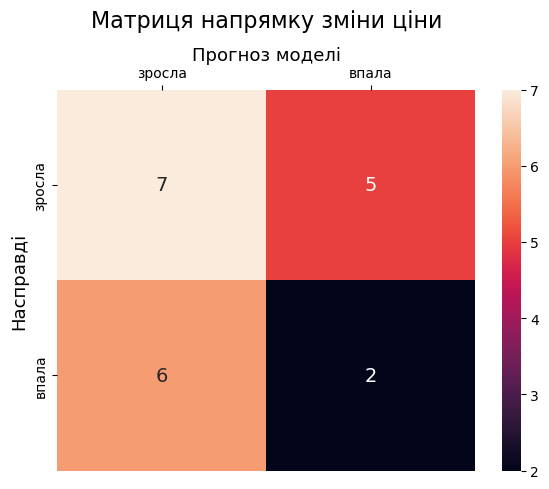

In [310]:
import seaborn as sns

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(matrix, annot=True, fmt='d', cmap='rocket', annot_kws={'size': 14}, ax=ax)
ax.set_title('Матриця напрямку зміни ціни', fontsize=16, pad=45)
ax.set_xlabel('Прогноз моделі', fontsize=13)
ax.set_ylabel('Насправді', fontsize=13)
ax.xaxis.set_label_position('top')
ax.xaxis.tick_top()
plt.tight_layout()
plt.show()

In [311]:
print(f"Кількість правильних передбачень: {conf_matrix[0, 0] + conf_matrix[1, 1]}")
print(f"Загальна кількість передбачень: {conf_matrix.sum()}")
print(f"Частка правильних: {accuracy_score(actual_dir, predicted_dir) * 100}%")

Кількість правильних передбачень: 9
Загальна кількість передбачень: 20
Частка правильних: 45.0%


**Висновок до завдання 15:**

| Метрика | Orange, % | Python (sklearn accuracy score), % |
|---|---|---|
| POCID | 45.0 | 45.0 |

MAE і RMSE показують, на скільки гривень модель помиляється, і не враховують, у який бік. Для рішення «купувати зараз чи чекати» важливий саме напрямок зміни ціни. Наша модель має малу похибку (RMSE 0.877 грн), але вгадує напрямок лише в 45 % випадків — гірше, ніж навмання. Тому для цього рішення модель не є некорисна.

**Загальний висновок**
---

Стабільної сезонності в ряді цін на соняшникову олію у Львові немає. Сила сезонності за робастним STL дорівнює 0.445, тобто формально потрапляє в зону середньої сезонності за шкалою з лекції, але сезонна складова не повторюється з року в рік: її розмах зменшується з 5.61 грн у 2014 році до майже нуля у 2017-му, а пік ціни щороку припадає на різні місяці.

Найкращим методом прогнозування виявився найпростіший наївний прогноз «як минулого місяця» (MAE 0.626 грн на 7 фолдах рухомого початку). Модель ARIMA(1,1,1) його не перевершила.

Точку зміни режиму знайдено в січні 2015 року: середня ціна зросла з 16.02 до 30.89 грн (t = 22.67), і ця точка значуща. Зовнішнє пояснення — девальвація гривні взимку 2014–2015 року.

Однаково названі метрики в Orange і Python дали різні числа, бо рахуються за різними формулами: Orange під назвою MAE рахує медіану абсолютних похибок, а MAPE — як відношення середньої похибки до середньої ціни. RMSE визначено однаково, тому він збігся, що підтверджує однакові дані й фолди в обох середовищах.

Через те, що ряд має лише 46 спостережень (менше ніж чотири повні роки), це обмежує перевірку моделі максимум 15 фолдами, тож оцінка POCID приблизна.

---
# Критерії оцінювання

| Бали | Умова |
|---|---|
| **0** | Ряд не розкладено або прогноз не побудовано. Робота не зарахована. |
| **2** | Виконано лише Частину 1: ряд розкладено й прогноз побудовано, але в Orange аналіз не відтворено. |
| **3** | Виконано обидві частини, проте прогноз не зіставлено з наївним базисом, а розбіжність результатів двох середовищ не пояснено. |
| **4** | Ряд розкладено на складові; прогноз зіставлено з наївним базисом за ретроспективною перевіркою з рухомим початком; той самий аналіз відтворено в Orange; зіставлено результати двох середовищ і пояснено розбіжність метрик. |

**Знімаються бали за:**

* графіки без пояснення вибору геометрії та шкали;
* числа без письмового висновку;
* прогноз без порівняння з базисом;
* висновок «метрики різні, бо середовища різні» без відтворення формул;
* зошит, який не виконується від початку до кінця.

---
# Декларація про використання штучного інтелекту

Використання інструментів штучного інтелекту під час виконання цієї роботи **дозволено**.
Умова одна: ви маєте розуміти кожен рядок зданого коду й кожне написане твердження
і бути готовим пояснити їх на захисті.

Заповніть таблицю. Якщо ШІ не використовувався, напишіть «не використовувався» в першому рядку
й залиште решту порожньою.

| Питання | Ваша відповідь |
|---|---|
| Які інструменти використано (назва, версія) | Claude (Anthropic), модель claude-opus-5-5 |
| Для яких саме завдань | написання коду, пояснення методів (1 - 15) |
| Що саме було згенеровано (код / текст / пояснення / виправлення помилок) | У більшості код, текст мінявся |
| Що ви змінили у згенерованому результаті й чому | Писала власними словами, без використання складних формулювань. |
| Що з отриманого ви **перевірили самостійно** і яким способом | Перевірила поріг сезонності, звіряла числа з висновками, додатково шукала інформацію по роботі з Orange. |
| Чи траплялися у відповідях ШІ помилки; якщо так — які | Не виникали. |

**Підтверджую, що розумію весь зданий код і всі зроблені висновки
та можу пояснити будь-яку їх частину на захисті роботи.**

Підпис: Паничевська Я.Е.  Дата: 10.27.2026